# Exploración de datos

Para ver cómo vienen los viajes antes de empezar a armar features.

Se usa el parquet unificado de `data/raw` y la nomenclatura de estaciones. Aquí solo exploramos; lo que sirva se pasa a `mibici/features.py` (#4).

No se lee `usuario_id` ni `genero`, por si el notebook se comparte.

## Ambiente

Correr esto con el `.venv` del proyecto, no con el Python del sistema. Si el kernel no existe, se crea desde la raíz del repo:

```bash
.venv/bin/python -m ipykernel install --user --name mibici --display-name "Python (.venv) mibici"
```

En este ambiente quedó así:

```
kernel : mibici  (Python (.venv) mibici)
python : /Users/gerardocarreno/Documents/MaestriaTecMonterrey/CuartoTrimestre/MLOps/Semana_5/TC5061-Proyecto-Equipo01/.venv/bin/python
```

Se elige en *Kernel → Change kernel* (Jupyter) o en *Select Kernel* (VS Code).

Si sale `ModuleNotFoundError: No module named 'mibici'`, es que la instalación editable apunta a otra carpeta; se rehace con `.venv/bin/python -m pip install -e .`. Mejor no usar `!pip install` dentro del notebook: instala en el kernel equivocado.

Este primer bloque importa y carga los datos.

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from loguru import logger

logger.disable("mibici")

from mibici.config import NOMENCLATURA_PARQUET_PATH, UNIFIED_TRIPS_PATH

plt.style.use("seaborn-v0_8-whitegrid")

viajes = pd.read_parquet(
    UNIFIED_TRIPS_PATH, columns=["inicio_viaje", "origen_id", "destino_id"]
)
nomen = pd.read_parquet(NOMENCLATURA_PARQUET_PATH)

viajes["mes"] = viajes["inicio_viaje"].dt.to_period("M")
viajes["hora"] = viajes["inicio_viaje"].dt.hour.astype("int8")
viajes["dia_semana"] = viajes["inicio_viaje"].dt.dayofweek.astype("int8")

print("viajes:", f"{len(viajes):,}")
print("del", viajes["inicio_viaje"].min(), "al", viajes["inicio_viaje"].max())
print("estaciones con viajes:", viajes["origen_id"].nunique(), "| en nomenclatura:", len(nomen))

viajes: 15,376,127
del 2023-05-01 00:00:03 al 2026-09-30 23:59:48
estaciones con viajes: 473 | en nomenclatura: 484


## 1. Viajes por mes

,viajes,estaciones_activas
mes,,
2023-05,364158,300
2023-06,339628,300
2023-07,331787,300
2026-07,388257,453
2026-08,393524,467
2026-09,490056,468


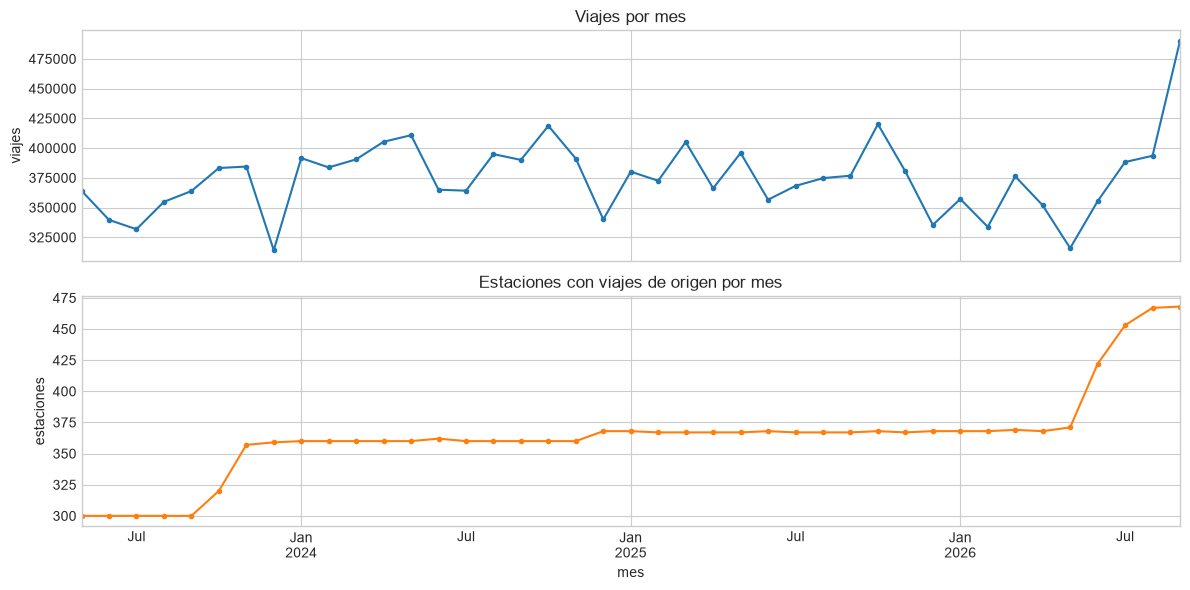

In [11]:
mensual = (
    viajes.groupby("mes")
    .agg(viajes=("origen_id", "size"), estaciones_activas=("origen_id", "nunique"))
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
mensual["viajes"].plot(ax=ax1, marker="o", ms=3, color="tab:blue")
ax1.set_title("Viajes por mes")
ax1.set_ylabel("viajes")

mensual["estaciones_activas"].plot(ax=ax2, marker="o", ms=3, color="tab:orange")
ax2.set_title("Estaciones con viajes de origen por mes")
ax2.set_ylabel("estaciones")
plt.tight_layout()

pd.concat([mensual.head(3), mensual.tail(3)])

Sube mes a mes. Lo de 2023 es porque las estaciones iban abriendo poco a poco: en mayo de 2023 había 300 activas y hoy 468.

## 2. Hora y día de la semana

horas con más viajes (%):
hora
18    9.25
8     7.75
17    7.45
19    7.13
15    6.63


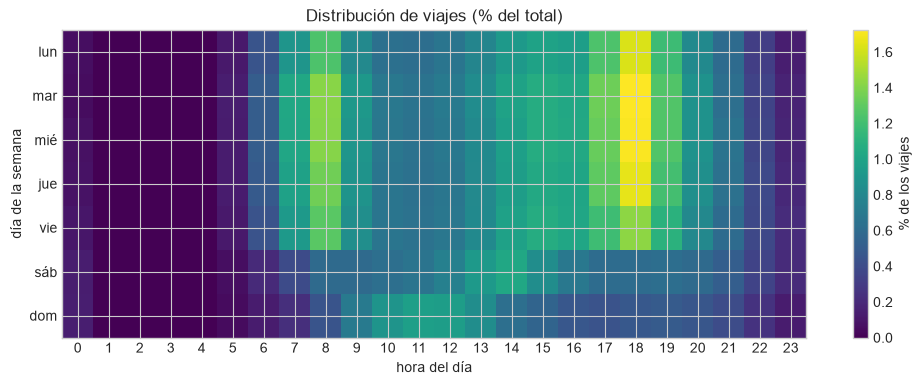

In [12]:
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
# 11 combinaciones día/hora no existen en el dato (madrugada entre semana),
# fill_value=0 evita que unstack las deje en NaN
calor = viajes.groupby(["dia_semana", "hora"]).size().unstack("hora", fill_value=0)
calor = calor.div(calor.values.sum()) * 100

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(calor.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(24))
ax.set_yticks(range(7), [dias[d] for d in calor.index])
ax.set_xlabel("hora del día")
ax.set_ylabel("día de la semana")
ax.set_title("Distribución de viajes (% del total)")
fig.colorbar(im, ax=ax, label="% de los viajes")

viajes_por_hora = viajes.groupby("hora").size() / len(viajes) * 100
print("horas con más viajes (%):")
print(viajes_por_hora.sort_values(ascending=False).head(5).round(2).to_string())

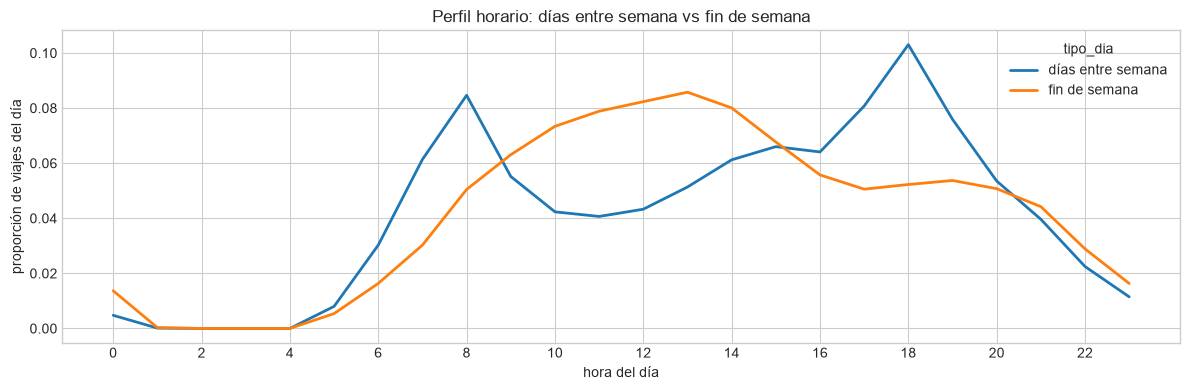

In [13]:
perfil = (
    viajes.assign(
        tipo_dia=viajes["dia_semana"].ge(5).map({True: "fin de semana", False: "días entre semana"})
    )
    .groupby(["tipo_dia", "hora"])
    .size()
    .unstack("tipo_dia", fill_value=0)
)
perfil = perfil.div(perfil.sum())

ax = perfil.plot(figsize=(12, 4), lw=2)
ax.set_title("Perfil horario: días entre semana vs fin de semana")
ax.set_xlabel("hora del día")
ax.set_ylabel("proporción de viajes del día")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()

## 3. Fin de semana y meses altos/bajos

entre semana 79.2%, fin de semana 20.8%


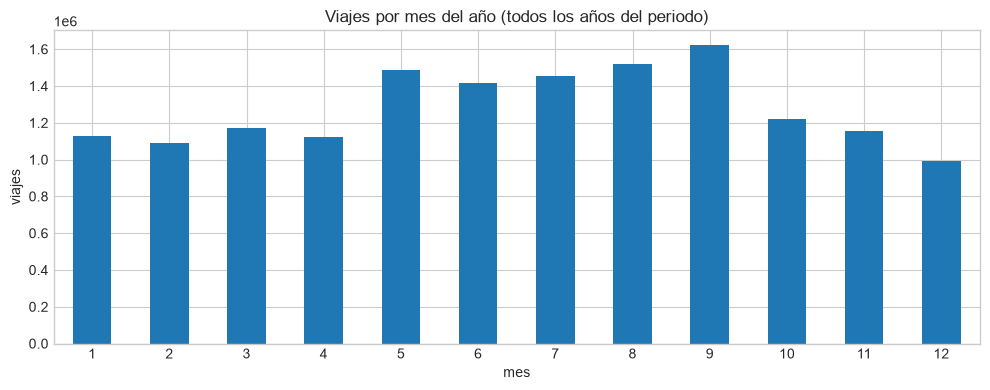

In [14]:
sazonal = viajes.groupby(viajes["inicio_viaje"].dt.month).size()
sazonal.index.name = "mes_del_anio"

ax = sazonal.plot(kind="bar", figsize=(10, 4), color="tab:blue", rot=0)
ax.set_title("Viajes por mes del año (todos los años del periodo)")
ax.set_xlabel("mes")
ax.set_ylabel("viajes")
plt.tight_layout()

print(f"entre semana {(viajes['dia_semana'].lt(5).mean() * 100):.1f}%, fin de semana {(viajes['dia_semana'].ge(5).mean() * 100):.1f}%")

Diciembre es el mes más flojo y octubre el mejor, igual en 2024 que en 2025. Agosto se queda en lo normal y junio-julio bajan por vacaciones.

El fin de semana aporta 20.8% de los viajes y la curva se aplana.

## 4. Estaciones que más se usan

,nombre,salidas,llegadas
51,(GDL-049) Lopez Cotilla / Penitenciaría,320631,398226
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,241992,286334
271,(GDL-198) Av. Alcalde / C. Hospital,235330,219563
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,226272,210671
52,(GDL-050) C.Pedro Moreno /Federalismo,201648,197274
50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,192254,198923
54,(GDL-052) Av. Juarez /16 de Septiembre,177627,187568
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,141780,85930
38,(GDL-036) C. Marcos Castellanos/ C. Morelos,132815,137549
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,128910,164081


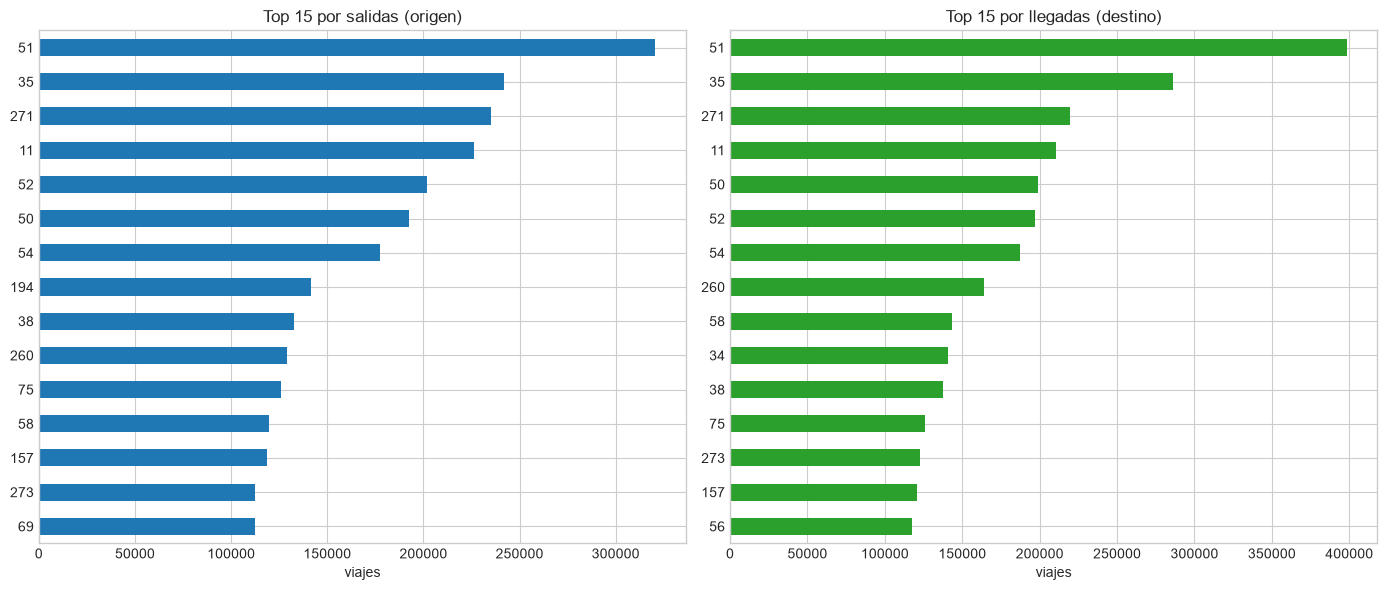

In [15]:
nombres = nomen.set_index("estacion_id")["nombre"]

salidas = viajes.groupby("origen_id").size().rename("salidas")
llegadas = viajes.groupby("destino_id").size().rename("llegadas")

top = pd.DataFrame({"salidas": salidas, "llegadas": llegadas}).join(nombres).fillna(0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
top["salidas"].nlargest(15).sort_values().plot.barh(ax=ax1, color="tab:blue")
ax1.set_title("Top 15 por salidas (origen)")
ax1.set_xlabel("viajes")
ax1.set_ylabel("")

top["llegadas"].nlargest(15).sort_values().plot.barh(ax=ax2, color="tab:green")
ax2.set_title("Top 15 por llegadas (destino)")
ax2.set_xlabel("viajes")
ax2.set_ylabel("")
plt.tight_layout()

top.nlargest(10, "salidas")[["nombre", "salidas", "llegadas"]]

## 5. Capacidad

anclajes en total: 8,171 (min 0 / max 39)
estaciones con capacidad 0: 4
con viajes pero sin nomenclatura: 2 -> [405, 407]


,nombre,capacidad,viajes_de_salida
estacion_id,,,
51,(GDL-049) Lopez Cotilla / Penitenciaría,39.0,320631.0
263,(GDL-190) C. Anahuac / Av. Revolución,31.0,43245.0
271,(GDL-198) Av. Alcalde / C. Hospital,31.0,235330.0
281,(GDL-208) Av. España / Av. Federalismo,31.0,74105.0
283,(GDL-210) Av. Washington / Calz. Independenci,31.0,66505.0
99,ex-(ZPN-009) C. Del Corral / C. Nicolás Bravo,0.0,0.0
109,ex-(ZPN-019) C. Cabecera Mpal. Juan Manuel / C.,0.0,0.0
116,ex-(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,0.0,0.0
138,ex-(ZPN-044),0.0,0.0


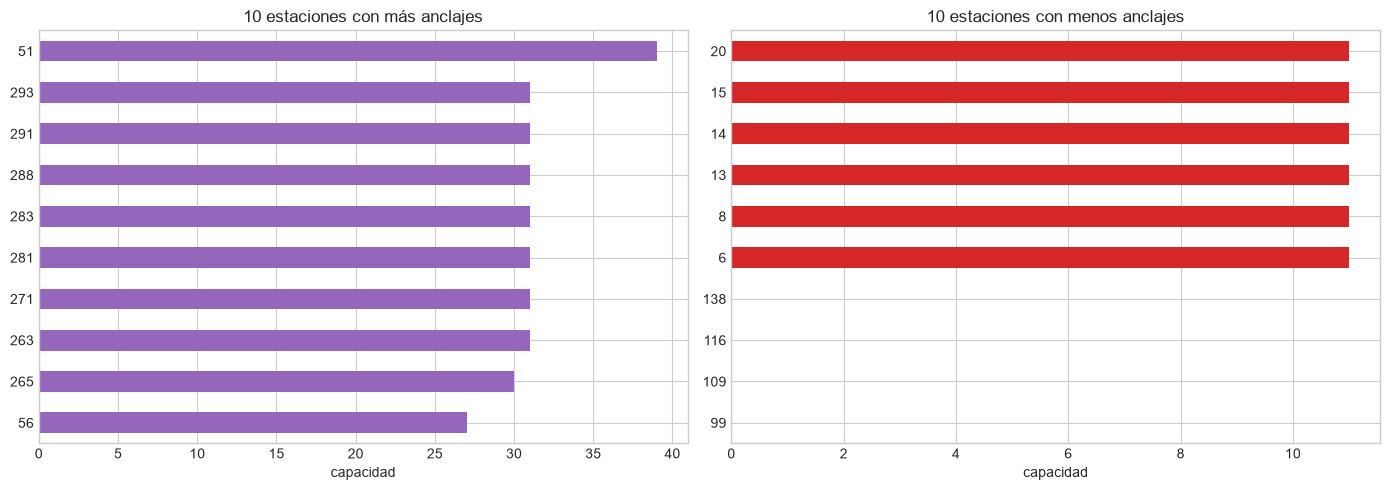

In [16]:
cap = nomen.set_index("estacion_id").join(salidas.rename("viajes_de_salida"))
cap["capacidad"] = cap["capacidad"].astype("float")
cap["viajes_de_salida"] = cap["viajes_de_salida"].fillna(0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
mayores = cap.nlargest(10, "capacidad")
menores = cap.nsmallest(10, "capacidad")

mayores["capacidad"].sort_values().plot.barh(ax=ax1, color="tab:purple")
ax1.set_title("10 estaciones con más anclajes")
ax1.set_xlabel("capacidad")
ax1.set_ylabel("")

menores["capacidad"].sort_values().plot.barh(ax=ax2, color="tab:red")
ax2.set_title("10 estaciones con menos anclajes")
ax2.set_xlabel("capacidad")
ax2.set_ylabel("")
plt.tight_layout()

sin_nom = sorted(int(x) for x in set(viajes["origen_id"]) - set(nomen["estacion_id"]))
print(f"anclajes en total: {int(cap['capacidad'].sum()):,} (min {int(cap['capacidad'].min())} / max {int(cap['capacidad'].max())})")
print("estaciones con capacidad 0:", int((cap["capacidad"] == 0).sum()))
print("con viajes pero sin nomenclatura:", len(sin_nom), "->", sin_nom)
pd.concat([mayores.head(5), menores.head(5)])[["nombre", "capacidad", "viajes_de_salida"]]

## Resumen

Entre mayo de 2023 y septiembre de 2026 se acumulan 15,376,127 viajes. Las estaciones activas pasaron de 300 a 468.

Lo más movido es a las 8 de la mañana y a las 6 de la tarde. El fin de semana aporta el 20.8% del total y la curva se aplana. Diciembre es el mes más flojo, octubre el mejor, y junio-julio bajan por vacaciones.

Las estaciones que más se usan están en el centro: López Cotilla, Hidalgo, Alcalde y Federalismo. En total hay 8,171 anclajes; 4 estaciones traen capacidad 0 y 2 no vienen en la nomenclatura, esas quedan en NaN en `features.py`.

## Qué sigue

Lo que sirva de aquí baja a `features.py` (estación por hora, calendario y lags). El target de P1 y los cortes de train/val/test están en `references/ml_canvas.md`. 